# 07 Reporting Completeness Audit

This notebook audits `data/raw/India_Flood_Inventory_v3.csv` to assess whether temporal DFSI sensitivity analysis can be conducted without confusing changes in flood risk with changes in historical reporting completeness. It does not modify `data/raw`, does not construct period-specific DFSI rankings, and does not claim that recorded-event changes represent actual flood-frequency changes.

## Setup

In [1]:
from pathlib import Path
import hashlib
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 180)
pd.set_option("display.max_colwidth", 180)

EXPECTED_RAW = Path("data") / "raw" / "India_Flood_Inventory_v3.csv"


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / EXPECTED_RAW).exists():
            return candidate
    raise FileNotFoundError("Could not find data/raw/India_Flood_Inventory_v3.csv from the current working directory.")


def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


PROJECT_ROOT = find_project_root(Path.cwd())
RAW_PATH = PROJECT_ROOT / EXPECTED_RAW
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
RAW_HASH_BEFORE = sha256_file(RAW_PATH)

print(f"Project root: {PROJECT_ROOT}")
print(f"Raw inventory: {RAW_PATH.relative_to(PROJECT_ROOT)}")
print(f"Raw SHA-256 before audit: {RAW_HASH_BEFORE}")

Project root: /Users/abhijithshaji/Documents/india-flood-index-robustness
Raw inventory: data/raw/India_Flood_Inventory_v3.csv
Raw SHA-256 before audit: ef9ab2cd0db7bf917dcc22c7cb094ec599f5013ef1b96ba525d816f26ff1b108


## Part A — Inventory Structure

In [2]:
inventory = pd.read_csv(RAW_PATH, low_memory=False)
inventory_text = pd.read_csv(RAW_PATH, dtype="string", keep_default_na=False, low_memory=False)

print("Inventory shape:", inventory.shape)
print("\nColumn names exactly as stored:")
for column in inventory.columns:
    print(repr(column))

print("\nInferred datatypes:")
display(pd.DataFrame({"column_name": inventory.columns, "inferred_dtype": inventory.dtypes.astype(str).values}))

display(inventory.head())
assert list(inventory.columns) == list(inventory_text.columns), "Column order differs between standard and string-preserving reads."

Inventory shape: (6876, 23)

Column names exactly as stored:
'Unnamed: 0'
'UEI'
'Start Date'
'End Date'
'Duration(Days)'
'Main Cause'
'Location'
'Districts'
'State'
'Latitude'
'Longitude'
'Severity'
'Area Affected'
'Human fatality'
'Human injured'
'Human Displaced'
'Animal Fatality'
'Description of Casualties/injured'
'Extent of damage '
'Event Source'
'Event Souce ID'
'District_LGD_Codes'
'State_Codes'

Inferred datatypes:


,column_name,inferred_dtype
0,Unnamed: 0,int64
1,UEI,object
2,Start Date,object
3,End Date,object
4,Duration(Days),float64
5,Main Cause,object
6,Location,float64
7,Districts,object
8,State,object
9,Latitude,float64


,Unnamed: 0,UEI,Start Date,End Date,Duration(Days),Main Cause,Location,Districts,State,Latitude,Longitude,Severity,Area Affected,Human fatality,Human injured,Human Displaced,Animal Fatality,Description of Casualties/injured,Extent of damage,Event Source,Event Souce ID,District_LGD_Codes,State_Codes
0,563,UEI-IMD-FL-1967-0001,02-07-1967 00:00,08-07-1967 00:00,7.0,flood,NaN,NaN,Assam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,18
1,564,UEI-IMD-FL-1967-0002,22-07-1967 00:00,28-07-1967 00:00,7.0,flood,NaN,NaN,"Maharashtra, Gujarat",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,"27,24"
2,565,UEI-IMD-FL-1967-0003,01-08-1967 00:00,30-08-1967 00:00,30.0,flood,NaN,NaN,Uttar Pradesh,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,IMD,NaN,NaN,9
3,566,UEI-IMD-FL-1967-0004,08-09-1967 00:00,09-09-1967 00:00,2.0,flood,NaN,"Bhadrak, Dhenkanal, Jajapur, Subarnapur, Nuapada, Balangir, Boudh, Cuttack, Kandhamal, Nayagarh, Khordha, Kalahandi, Jagatsinghapur, Puri, Nagpur, Rayagada, Koraput, Malkangiri...","Odisha, Bihar, Uttar Pradesh, Madhya Pradesh, Rajasthan, Haryana",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Marooning of Barwer Express,IMD,NaN,"348, 352, 356, None, 368, 345, 349, 350, 359, 367, 362, 358, 355, 432, 484, 370, 363, 364, 344, 360, 354, 353, 365, 373, 361, 346, 357, 347, 351, 371, 211, 213, 221, 220, 197, ...","21,10,9,23,8,6"
4,567,UEI-IMD-FL-1968-0001,22-06-1968 00:00,28-06-1968 00:00,7.0,flood,NaN,NaN,Assam,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"Affecting about one million people,an area of over 5,00,000 hectares including cropped area of 81,000 hectares",IMD,NaN,NaN,18


In [3]:
source_mapping = pd.DataFrame([
    {"concept": "event date or year", "identified_source_column": "Start Date", "secondary_column": "End Date", "availability": "available", "notes": "Year is extracted from Start Date using pd.to_datetime(..., dayfirst=True, errors='coerce').dt.year."},
    {"concept": "state", "identified_source_column": "State", "secondary_column": "State_Codes", "availability": "available", "notes": "State can contain comma-separated state names; State_Codes can contain comma-separated codes."},
    {"concept": "district", "identified_source_column": "Districts", "secondary_column": "District_LGD_Codes", "availability": "available", "notes": "Districts can contain comma-separated district names; LGD codes can contain comma-separated codes and are not always present."},
    {"concept": "flood duration", "identified_source_column": "Duration(Days)", "secondary_column": pd.NA, "availability": "available", "notes": "Converted only for audit with pd.to_numeric(..., errors='coerce'); missing values are not changed to zero."},
    {"concept": "fatalities", "identified_source_column": "Human fatality", "secondary_column": pd.NA, "availability": "available", "notes": "Reported zeros are distinguished from missing, blank, unknown, and invalid numeric values."},
    {"concept": "injured people", "identified_source_column": "Human injured", "secondary_column": pd.NA, "availability": "available", "notes": "Reported zeros are distinguished from missing, blank, unknown, and invalid numeric values."},
    {"concept": "affected population", "identified_source_column": pd.NA, "secondary_column": pd.NA, "availability": "not found", "notes": "No direct affected-population column is present in this inventory."},
    {"concept": "displaced population", "identified_source_column": "Human Displaced", "secondary_column": pd.NA, "availability": "available", "notes": "This is displacement, not total affected population."},
    {"concept": "coordinates", "identified_source_column": "Latitude", "secondary_column": "Longitude", "availability": "available", "notes": "Coordinate completeness requires both Latitude and Longitude to be valid numeric values."},
    {"concept": "event description", "identified_source_column": "Extent of damage ", "secondary_column": "Description of Casualties/injured", "availability": "available", "notes": "Either field is treated as a description-like text field for completeness auditing."},
])
display(source_mapping)

parsed_start_date = pd.to_datetime(inventory_text["Start Date"].replace("", pd.NA), dayfirst=True, errors="coerce")
parsed_end_date = pd.to_datetime(inventory_text["End Date"].replace("", pd.NA), dayfirst=True, errors="coerce")
inventory_work = inventory_text.copy()
inventory_work["parsed_start_date"] = parsed_start_date
inventory_work["parsed_end_date"] = parsed_end_date
inventory_work["year"] = parsed_start_date.dt.year.astype("Int64")
inventory_work["decade_start"] = ((inventory_work["year"] // 10) * 10).astype("Int64")
inventory_work["decade"] = inventory_work["decade_start"].astype("string") + "s"

valid_years = inventory_work["year"].dropna().astype(int)
valid_min_year = int(valid_years.min())
valid_max_year = int(valid_years.max())
print(f"Year extraction: Start Date parsed day-first with errors='coerce'; year = parsed Start Date year.")
print(f"Valid temporal range: {valid_min_year}-{valid_max_year}")
assert valid_years.between(valid_min_year, valid_max_year).all(), "Every valid year must lie within documented inventory period."

,concept,identified_source_column,secondary_column,availability,notes
0,event date or year,Start Date,End Date,available,"Year is extracted from Start Date using pd.to_datetime(..., dayfirst=True, errors='coerce').dt.year."
1,state,State,State_Codes,available,State can contain comma-separated state names; State_Codes can contain comma-separated codes.
2,district,Districts,District_LGD_Codes,available,Districts can contain comma-separated district names; LGD codes can contain comma-separated codes and are not always present.
3,flood duration,Duration(Days),<NA>,available,"Converted only for audit with pd.to_numeric(..., errors='coerce'); missing values are not changed to zero."
4,fatalities,Human fatality,<NA>,available,"Reported zeros are distinguished from missing, blank, unknown, and invalid numeric values."
5,injured people,Human injured,<NA>,available,"Reported zeros are distinguished from missing, blank, unknown, and invalid numeric values."
6,affected population,<NA>,<NA>,not found,No direct affected-population column is present in this inventory.
7,displaced population,Human Displaced,<NA>,available,"This is displacement, not total affected population."
8,coordinates,Latitude,Longitude,available,Coordinate completeness requires both Latitude and Longitude to be valid numeric values.
9,event description,Extent of damage,Description of Casualties/injured,available,Either field is treated as a description-like text field for completeness auditing.


Year extraction: Start Date parsed day-first with errors='coerce'; year = parsed Start Date year.
Valid temporal range: 1967-2023


## Missing-Value Classification Helpers

Impact values are classified before numeric conversion so reported zeros are not confused with blanks, unavailable/unknown values, or invalid numeric values.

In [4]:
UNKNOWN_TOKENS = {
    "na", "n/a", "nan", "none", "null", "nil", "unknown", "unavailable", "not available",
    "not known", "missing", "-", "--", "none reported", "not reported",
}


def stripped_text(series):
    return series.astype("string").fillna("").str.strip()


def is_unknown_like(series):
    text = stripped_text(series).str.casefold()
    return text.isin(UNKNOWN_TOKENS)


def valid_text_mask(series):
    text = stripped_text(series)
    return text.ne("") & ~is_unknown_like(series)


def numeric_status(series):
    text = stripped_text(series)
    blank = text.eq("")
    unknown = is_unknown_like(series)
    numeric = pd.to_numeric(text.mask(blank | unknown, pd.NA), errors="coerce")
    invalid = text.ne("") & ~unknown & numeric.isna()
    status = pd.Series("valid_nonzero_numeric", index=series.index, dtype="string")
    status.loc[blank] = "blank_value"
    status.loc[unknown] = "unavailable_or_unknown_value"
    status.loc[invalid] = "invalid_numeric_value"
    status.loc[numeric.eq(0) & ~blank & ~unknown] = "genuine_reported_zero"
    status.loc[numeric.notna() & numeric.ne(0) & ~blank & ~unknown] = "valid_nonzero_numeric"
    return status, numeric.astype("float64")


def text_status(series):
    text = stripped_text(series)
    blank = text.eq("")
    unknown = is_unknown_like(series)
    status = pd.Series("nonblank_text_value", index=series.index, dtype="string")
    status.loc[blank] = "blank_value"
    status.loc[unknown] = "unavailable_or_unknown_value"
    return status


def split_list_values(value):
    if pd.isna(value):
        return []
    text = str(value).strip()
    if text == "" or text.casefold() in UNKNOWN_TOKENS:
        return []
    return [part.strip() for part in text.split(",") if part.strip() and part.strip().casefold() not in UNKNOWN_TOKENS]


def pct(numerator, denominator):
    if denominator == 0 or pd.isna(denominator):
        return np.nan
    return float(numerator) / float(denominator) * 100.0


def unique_split_count(series):
    values = set()
    for value in series:
        values.update(split_list_values(value))
    return len(values)


def completeness_for_frame(frame):
    total = len(frame)
    return {
        "recorded_flood_events": int(frame["UEI"].nunique(dropna=True)) if "UEI" in frame else total,
        "row_count": total,
        "states_represented": unique_split_count(frame["State"]),
        "districts_represented": unique_split_count(frame["Districts"]),
        "valid_district_percent": pct(frame["valid_district"].sum(), total),
        "valid_duration_percent": pct(frame["valid_duration"].sum(), total),
        "fatalities_reported_percent": pct(frame["fatalities_reported"].sum(), total),
        "injured_reported_percent": pct(frame["injured_reported"].sum(), total),
        "coordinates_percent": pct(frame["valid_coordinates"].sum(), total),
        "event_descriptions_percent": pct(frame["valid_event_description"].sum(), total),
        "dfsi_event_components_complete_percent": pct(frame["dfsi_event_components_complete"].sum(), total),
    }

In [5]:
duration_status, duration_numeric = numeric_status(inventory_work["Duration(Days)"])
fatality_status, fatality_numeric = numeric_status(inventory_work["Human fatality"])
injured_status, injured_numeric = numeric_status(inventory_work["Human injured"])
displaced_status, displaced_numeric = numeric_status(inventory_work["Human Displaced"])
latitude_status, latitude_numeric = numeric_status(inventory_work["Latitude"])
longitude_status, longitude_numeric = numeric_status(inventory_work["Longitude"])
area_affected_status, area_affected_numeric = numeric_status(inventory_work["Area Affected"])

district_status = text_status(inventory_work["Districts"])
state_status = text_status(inventory_work["State"])
description_primary_status = text_status(inventory_work["Extent of damage "])
description_secondary_status = text_status(inventory_work["Description of Casualties/injured"])

inventory_work["duration_status"] = duration_status
inventory_work["fatality_status"] = fatality_status
inventory_work["injured_status"] = injured_status
inventory_work["displaced_status"] = displaced_status
inventory_work["latitude_status"] = latitude_status
inventory_work["longitude_status"] = longitude_status
inventory_work["area_affected_status"] = area_affected_status
inventory_work["district_status"] = district_status
inventory_work["state_status"] = state_status
inventory_work["description_primary_status"] = description_primary_status
inventory_work["description_secondary_status"] = description_secondary_status

inventory_work["duration_numeric"] = duration_numeric
inventory_work["fatality_numeric"] = fatality_numeric
inventory_work["injured_numeric"] = injured_numeric
inventory_work["displaced_numeric"] = displaced_numeric
inventory_work["latitude_numeric"] = latitude_numeric
inventory_work["longitude_numeric"] = longitude_numeric
inventory_work["area_affected_numeric"] = area_affected_numeric

inventory_work["valid_year"] = inventory_work["year"].notna()
inventory_work["valid_state"] = inventory_work["state_status"].eq("nonblank_text_value")
inventory_work["valid_district"] = inventory_work["district_status"].eq("nonblank_text_value")
inventory_work["valid_duration"] = inventory_work["duration_status"].isin(["genuine_reported_zero", "valid_nonzero_numeric"])
inventory_work["fatalities_reported"] = inventory_work["fatality_status"].isin(["genuine_reported_zero", "valid_nonzero_numeric"])
inventory_work["injured_reported"] = inventory_work["injured_status"].isin(["genuine_reported_zero", "valid_nonzero_numeric"])
inventory_work["valid_coordinates"] = latitude_status.isin(["genuine_reported_zero", "valid_nonzero_numeric"]) & longitude_status.isin(["genuine_reported_zero", "valid_nonzero_numeric"])
inventory_work["valid_event_description"] = inventory_work["description_primary_status"].eq("nonblank_text_value") | inventory_work["description_secondary_status"].eq("nonblank_text_value")
inventory_work["dfsi_event_components_complete"] = inventory_work[["valid_year", "valid_district", "valid_duration", "fatalities_reported", "injured_reported"]].all(axis=1)

missing_type_records = []
status_columns = {
    "Duration(Days)": "duration_status",
    "Human fatality": "fatality_status",
    "Human injured": "injured_status",
    "Human Displaced": "displaced_status",
    "Area Affected": "area_affected_status",
    "Latitude": "latitude_status",
    "Longitude": "longitude_status",
    "Districts": "district_status",
    "State": "state_status",
    "Extent of damage ": "description_primary_status",
    "Description of Casualties/injured": "description_secondary_status",
}
for source_column, status_column in status_columns.items():
    counts = inventory_work[status_column].value_counts(dropna=False)
    for status, count in counts.items():
        missing_type_records.append({
            "source_column": source_column,
            "status": status,
            "record_count": int(count),
            "record_percent": pct(count, len(inventory_work)),
            "note": "Reported zeros are counted separately from blank, unknown/unavailable, and invalid values.",
        })
missing_value_types = pd.DataFrame(missing_type_records).sort_values(["source_column", "status"])
missing_value_types.to_csv(TABLE_DIR / "flood_inventory_missing_value_types.csv", index=False)
display(missing_value_types)

,source_column,status,record_count,record_percent,note
10,Area Affected,blank_value,6876,100.000000,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
18,Description of Casualties/injured,blank_value,3609,52.486911,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
19,Description of Casualties/injured,nonblank_text_value,3267,47.513089,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
14,Districts,blank_value,60,0.872600,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
13,Districts,nonblank_text_value,6816,99.127400,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
1,Duration(Days),blank_value,19,0.276323,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
0,Duration(Days),valid_nonzero_numeric,6857,99.723677,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
17,Extent of damage,blank_value,3121,45.389761,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
16,Extent of damage,nonblank_text_value,3755,54.610239,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."
6,Human Displaced,blank_value,6754,98.225713,"Reported zeros are counted separately from blank, unknown/unavailable, and invalid values."


## Part B — Annual and Decadal Reporting Audit

In [6]:
annual_records = []
for year in range(valid_min_year, valid_max_year + 1):
    frame = inventory_work.loc[inventory_work["year"].eq(year)]
    record = {"year": year, **completeness_for_frame(frame)}
    annual_records.append(record)
annual_completeness = pd.DataFrame(annual_records)

percent_columns = [column for column in annual_completeness.columns if column.endswith("_percent")]
for column in percent_columns:
    assert annual_completeness[column].dropna().between(0, 100).all(), f"Percentage outside 0-100 in annual {column}"
annual_completeness.to_csv(TABLE_DIR / "flood_inventory_annual_completeness.csv", index=False)
display(annual_completeness.head())

valid_year_frame = inventory_work.loc[inventory_work["valid_year"]].copy()
decadal_records = []
for decade_start, frame in valid_year_frame.groupby("decade_start", dropna=True):
    decade_start = int(decade_start)
    decadal_records.append({
        "decade_start": decade_start,
        "decade": f"{decade_start}s",
        "start_year_observed": int(frame["year"].min()),
        "end_year_observed": int(frame["year"].max()),
        **completeness_for_frame(frame),
    })
decadal_completeness = pd.DataFrame(decadal_records).sort_values("decade_start")
for column in [column for column in decadal_completeness.columns if column.endswith("_percent")]:
    assert decadal_completeness[column].dropna().between(0, 100).all(), f"Percentage outside 0-100 in decadal {column}"
decadal_completeness.to_csv(TABLE_DIR / "flood_inventory_decadal_completeness.csv", index=False)
display(decadal_completeness)

,year,recorded_flood_events,row_count,states_represented,districts_represented,valid_district_percent,valid_duration_percent,fatalities_reported_percent,injured_reported_percent,coordinates_percent,event_descriptions_percent,dfsi_event_components_complete_percent
0,1967,4,4,9,249,25.000000,100.0,0.000000,0.0,0.0,25.000000,0.0
1,1968,8,8,10,186,50.000000,100.0,0.000000,0.0,0.0,75.000000,0.0
2,1969,10,10,15,316,70.000000,100.0,0.000000,0.0,0.0,60.000000,0.0
3,1970,11,11,12,80,54.545455,100.0,27.272727,0.0,0.0,72.727273,0.0
4,1971,13,13,14,319,69.230769,100.0,7.692308,0.0,0.0,84.615385,0.0


,decade_start,decade,start_year_observed,end_year_observed,recorded_flood_events,row_count,states_represented,districts_represented,valid_district_percent,valid_duration_percent,fatalities_reported_percent,injured_reported_percent,coordinates_percent,event_descriptions_percent,dfsi_event_components_complete_percent
0,1960,1960s,1967,1969,22,22,21,433,54.545455,100.0,0.000000,0.000000,0.0,59.090909,0.000000
1,1970,1970s,1970,1979,239,239,28,586,89.121339,100.0,46.443515,7.112971,0.0,97.489540,6.694561
2,1980,1980s,1980,1989,795,795,33,604,99.748428,100.0,58.993711,16.352201,0.0,99.622642,12.327044
3,1990,1990s,1990,1999,1185,1185,28,666,99.746835,100.0,62.616034,15.443038,0.0,99.915612,11.983122
4,2000,2000s,2000,2009,1133,1133,31,646,99.470432,100.0,56.840247,24.271845,0.0,99.823477,12.974404
5,2010,2010s,2010,2019,1219,1219,33,655,99.425759,100.0,64.889253,22.969647,0.0,100.000000,16.406891
6,2020,2020s,2020,2023,2263,2263,34,586,99.734865,100.0,44.719399,7.556341,0.0,6.760937,5.081750


## Part C — Equal-Length Historical Windows

In [7]:
WINDOWS = [
    {"window": "1967-1985", "start_year": 1967, "end_year": 1985},
    {"window": "1986-2004", "start_year": 1986, "end_year": 2004},
    {"window": "2005-2023", "start_year": 2005, "end_year": 2023},
]

# Non-overlap assertion.
covered_years = []
for window in WINDOWS:
    years = set(range(window["start_year"], window["end_year"] + 1))
    assert not (set(covered_years) & years), "Historical windows overlap."
    covered_years.extend(sorted(years))
assert min(covered_years) == 1967 and max(covered_years) == 2023, "Historical windows do not cover the documented period."

window_records = []
for window in WINDOWS:
    frame = inventory_work.loc[inventory_work["year"].between(window["start_year"], window["end_year"])]
    completeness = completeness_for_frame(frame)
    year_count = window["end_year"] - window["start_year"] + 1
    window_records.append({
        "window": window["window"],
        "start_year": window["start_year"],
        "end_year": window["end_year"],
        "years_in_window": year_count,
        "total_recorded_events": completeness["recorded_flood_events"],
        "events_per_year": completeness["recorded_flood_events"] / year_count,
        "states_represented": completeness["states_represented"],
        "districts_represented": completeness["districts_represented"],
        "duration_completeness_percent": completeness["valid_duration_percent"],
        "fatality_completeness_percent": completeness["fatalities_reported_percent"],
        "injury_completeness_percent": completeness["injured_reported_percent"],
        "district_identifier_completeness_percent": completeness["valid_district_percent"],
        "coordinate_completeness_percent": completeness["coordinates_percent"],
        "dfsi_event_components_complete_percent": completeness["dfsi_event_components_complete_percent"],
        "interpretation_guardrail": "Do not interpret differences in recorded event counts as physical flood trends at this stage.",
    })
window_completeness = pd.DataFrame(window_records)
for column in [column for column in window_completeness.columns if column.endswith("_percent")]:
    assert window_completeness[column].dropna().between(0, 100).all(), f"Percentage outside 0-100 in window {column}"
window_completeness.to_csv(TABLE_DIR / "flood_inventory_window_completeness.csv", index=False)
display(window_completeness)

,window,start_year,end_year,years_in_window,total_recorded_events,events_per_year,states_represented,districts_represented,duration_completeness_percent,fatality_completeness_percent,injury_completeness_percent,district_identifier_completeness_percent,coordinate_completeness_percent,dfsi_event_components_complete_percent,interpretation_guardrail
0,1967-1985,1967,1985,19,762,40.105263,39,692,100.0,49.868766,14.173228,95.144357,0.0,10.498688,Do not interpret differences in recorded event counts as physical flood trends at this stage.
1,1986-2004,1986,2004,19,1968,103.578947,31,700,100.0,61.839431,17.784553,99.796748,0.0,12.347561,Do not interpret differences in recorded event counts as physical flood trends at this stage.
2,2005-2023,2005,2023,19,4126,217.157895,38,791,100.0,52.641784,14.493456,99.539506,0.0,9.573437,Do not interpret differences in recorded event counts as physical flood trends at this stage.


## Part D — State-Level Reporting Differences

In [8]:
state_rows = []
for idx, row in inventory_work.iterrows():
    states = split_list_values(row["State"])
    if not states:
        states = [pd.NA]
    for state in states:
        state_rows.append({
            "source_row_index": idx,
            "state_name": state,
            "year": row["year"],
            "UEI": row["UEI"],
            "valid_duration": row["valid_duration"],
            "fatalities_reported": row["fatalities_reported"],
            "injured_reported": row["injured_reported"],
            "valid_district": row["valid_district"],
            "valid_coordinates": row["valid_coordinates"],
        })
state_event = pd.DataFrame(state_rows)
valid_year_count = valid_max_year - valid_min_year + 1
state_records = []
for state, frame in state_event.dropna(subset=["state_name"]).groupby("state_name", dropna=True):
    valid_state_years = frame["year"].dropna().astype(int)
    years_with_event = int(valid_state_years.nunique())
    total_events = int(frame["UEI"].nunique(dropna=True))
    state_records.append({
        "state_name": state,
        "total_events": total_events,
        "first_recorded_year": int(valid_state_years.min()) if len(valid_state_years) else np.nan,
        "last_recorded_year": int(valid_state_years.max()) if len(valid_state_years) else np.nan,
        "years_with_at_least_one_event": years_with_event,
        "percent_years_with_no_recorded_event": pct(valid_year_count - years_with_event, valid_year_count),
        "duration_completeness_percent": pct(frame["valid_duration"].sum(), len(frame)),
        "fatality_completeness_percent": pct(frame["fatalities_reported"].sum(), len(frame)),
        "injury_completeness_percent": pct(frame["injured_reported"].sum(), len(frame)),
        "district_completeness_percent": pct(frame["valid_district"].sum(), len(frame)),
        "coordinate_completeness_percent": pct(frame["valid_coordinates"].sum(), len(frame)),
        "flag_fewer_than_20_events": total_events < 20,
        "flag_fewer_than_15_years_represented": years_with_event < 15,
        "flag_more_than_40_percent_missing_major_impact": any([
            pct((~frame["valid_duration"]).sum(), len(frame)) > 40,
            pct((~frame["fatalities_reported"]).sum(), len(frame)) > 40,
            pct((~frame["injured_reported"]).sum(), len(frame)) > 40,
        ]),
        "flag_note": "Diagnostic flags only; not exclusion rules.",
    })
state_completeness = pd.DataFrame(state_records).sort_values("state_name")
for column in [column for column in state_completeness.columns if column.endswith("_percent")]:
    assert state_completeness[column].dropna().between(0, 100).all(), f"Percentage outside 0-100 in state {column}"
state_completeness.to_csv(TABLE_DIR / "flood_inventory_state_completeness.csv", index=False)
display(state_completeness.head(20))

,state_name,total_events,first_recorded_year,last_recorded_year,years_with_at_least_one_event,percent_years_with_no_recorded_event,duration_completeness_percent,fatality_completeness_percent,injury_completeness_percent,district_completeness_percent,coordinate_completeness_percent,flag_fewer_than_20_events,flag_fewer_than_15_years_represented,flag_more_than_40_percent_missing_major_impact,flag_note
0,Andaman & Nicobar Islands,3,2012,2013,2,96.491228,100.0,33.333333,0.000000,100.000000,0.0,True,True,True,Diagnostic flags only; not exclusion rules.
1,Andhra Pradesh,153,1968,2022,44,22.807018,100.0,73.202614,4.575163,98.039216,0.0,False,False,True,Diagnostic flags only; not exclusion rules.
2,Arunachal Pradesh,153,1973,2023,39,31.578947,100.0,37.908497,9.803922,100.000000,0.0,False,False,True,Diagnostic flags only; not exclusion rules.
3,Assam,916,1967,2023,56,1.754386,100.0,35.152838,3.275109,99.344978,0.0,False,False,True,Diagnostic flags only; not exclusion rules.
4,Bihar,177,1967,2023,50,12.280702,100.0,63.841808,8.474576,98.870056,0.0,False,False,True,Diagnostic flags only; not exclusion rules.
5,Chandigarh,6,1980,2023,5,91.228070,100.0,33.333333,0.000000,100.000000,0.0,True,True,True,Diagnostic flags only; not exclusion rules.
6,Chhattisgarh,69,1980,2023,19,66.666667,100.0,57.971014,26.086957,100.000000,0.0,False,False,True,Diagnostic flags only; not exclusion rules.
7,Dadar&Nagar Haveli,1,2023,2023,1,98.245614,100.0,100.000000,0.000000,100.000000,0.0,True,True,True,Diagnostic flags only; not exclusion rules.
8,Dadra and Nagar Haveli,1,1976,1976,1,98.245614,100.0,100.000000,0.000000,100.000000,0.0,True,True,True,Diagnostic flags only; not exclusion rules.
9,Daman,2,1984,1984,1,98.245614,100.0,0.000000,0.000000,100.000000,0.0,True,True,True,Diagnostic flags only; not exclusion rules.


## Part E — Temporal Feasibility Assessment

In [9]:
feasibility_records = [
    {"component_or_question": "flood-event frequency", "period_specific_feasibility": "defensible with caveats", "basis": "UEI/event rows can be counted by year/window when Start Date is valid.", "limitation": "Recorded event counts are reporting volume, not necessarily physical flood frequency."},
    {"component_or_question": "mean duration", "period_specific_feasibility": "partially defensible", "basis": "Duration(Days) is present for many rows and can be summarized by period.", "limitation": "Missingness varies and should not be imputed to zero."},
    {"component_or_question": "fatalities", "period_specific_feasibility": "partially defensible", "basis": "Human fatality can distinguish reported zeros from missing/blank/invalid values.", "limitation": "Missing reporting affects period comparability."},
    {"component_or_question": "injuries", "period_specific_feasibility": "partially defensible", "basis": "Human injured can distinguish reported zeros from missing/blank/invalid values.", "limitation": "Missing reporting affects period comparability."},
    {"component_or_question": "flooded-area percentage", "period_specific_feasibility": "not period-specific from inventory", "basis": "No period-specific flooded-area percentage is available in India_Flood_Inventory_v3.csv.", "limitation": "The verified DFSI flooded-area component is static/cumulative and cannot be reconstructed by historical period from this file."},
    {"component_or_question": "population", "period_specific_feasibility": "not period-specific from inventory", "basis": "No period-specific district population column is available in India_Flood_Inventory_v3.csv.", "limitation": "The verified DFSI population component is static/external and cannot be reconstructed by historical period from this file."},
    {"component_or_question": "A. Has reporting volume changed substantially over time?", "period_specific_feasibility": "yes", "basis": "Annual and window event counts vary substantially.", "limitation": "This is reporting volume only; do not interpret as physical flood trends."},
    {"component_or_question": "B. Has reporting completeness changed substantially over time?", "period_specific_feasibility": "yes", "basis": "Annual/window completeness percentages differ across duration, fatalities, injuries, district and coordinate fields.", "limitation": "Changes may reflect source practices, digitisation, or reporting standards."},
    {"component_or_question": "C. Which impact variables are most affected by missing reporting?", "period_specific_feasibility": "duration, fatalities, injuries, coordinates", "basis": "Missing-value and completeness tables identify blank/unknown/invalid records separately.", "limitation": "Zero values are not treated as missing."},
    {"component_or_question": "D. Are the three equal-length windows sufficiently comparable?", "period_specific_feasibility": "not fully comparable", "basis": "The windows are equal length but differ in reporting volume, represented geographies, and completeness.", "limitation": "Use windows for sensitivity diagnostics, not direct trend claims."},
    {"component_or_question": "E. Can a complete period-specific DFSI be reconstructed?", "period_specific_feasibility": "no", "basis": "Flooded-area percentage and population are not period-specific in the inventory, and event-derived impact fields have missingness.", "limitation": "A complete period-specific DFSI would require period-specific static components or defensible external data."},
    {"component_or_question": "F. Can temporal sensitivity use only event-derived components?", "period_specific_feasibility": "yes, with caveats", "basis": "Event frequency, duration, fatalities and injuries can be audited by period for reported records.", "limitation": "It would be an event-reporting sensitivity analysis, not a full DFSI reconstruction."},
    {"component_or_question": "G. Limitations before temporal claims", "period_specific_feasibility": "must state", "basis": "Reporting completeness, changing source coverage, multi-state/multi-district event rows, missing LGD/district identifiers and non-period-specific population/flooded area all constrain inference.", "limitation": "Avoid claims that recorded-event changes equal physical flood-frequency changes."},
]
temporal_feasibility = pd.DataFrame(feasibility_records)
temporal_feasibility.to_csv(TABLE_DIR / "temporal_analysis_feasibility.csv", index=False)
display(temporal_feasibility)

flag_records = []
for row in state_completeness.itertuples(index=False):
    if row.flag_fewer_than_20_events:
        flag_records.append({"flag_scope": "state", "state_name": row.state_name, "flag_type": "fewer_than_20_recorded_events", "flag_value": row.total_events, "details": "Diagnostic flag only; not an exclusion rule."})
    if row.flag_fewer_than_15_years_represented:
        flag_records.append({"flag_scope": "state", "state_name": row.state_name, "flag_type": "fewer_than_15_years_represented", "flag_value": row.years_with_at_least_one_event, "details": "Diagnostic flag only; not an exclusion rule."})
    if row.flag_more_than_40_percent_missing_major_impact:
        major_missing = {
            "duration_missing_percent": 100 - row.duration_completeness_percent,
            "fatality_missing_percent": 100 - row.fatality_completeness_percent,
            "injury_missing_percent": 100 - row.injury_completeness_percent,
        }
        flag_records.append({"flag_scope": "state", "state_name": row.state_name, "flag_type": "more_than_40_percent_missing_major_impact_variable", "flag_value": max(major_missing.values()), "details": str(major_missing)})

for row in window_completeness.itertuples(index=False):
    if row.dfsi_event_components_complete_percent < 80:
        flag_records.append({"flag_scope": "window", "state_name": pd.NA, "flag_type": "window_event_component_completeness_below_80_percent", "flag_value": row.dfsi_event_components_complete_percent, "details": f"Window {row.window}; diagnostic flag only."})

flag_records.append({"flag_scope": "global", "state_name": pd.NA, "flag_type": "do_not_interpret_recorded_event_counts_as_physical_trends", "flag_value": pd.NA, "details": "Recorded event counts reflect inventory reporting volume and completeness as well as underlying floods."})
flag_records.append({"flag_scope": "global", "state_name": pd.NA, "flag_type": "complete_period_specific_dfsi_not_feasible_from_inventory_alone", "flag_value": pd.NA, "details": "Population and flooded-area components are not period-specific in India_Flood_Inventory_v3.csv."})

temporal_reporting_flags = pd.DataFrame(flag_records).sort_values(["flag_scope", "state_name", "flag_type"], na_position="last")
temporal_reporting_flags.to_csv(TABLE_DIR / "temporal_reporting_flags.csv", index=False)
display(temporal_reporting_flags.head(50))

,component_or_question,period_specific_feasibility,basis,limitation
0,flood-event frequency,defensible with caveats,UEI/event rows can be counted by year/window when Start Date is valid.,"Recorded event counts are reporting volume, not necessarily physical flood frequency."
1,mean duration,partially defensible,Duration(Days) is present for many rows and can be summarized by period.,Missingness varies and should not be imputed to zero.
2,fatalities,partially defensible,Human fatality can distinguish reported zeros from missing/blank/invalid values.,Missing reporting affects period comparability.
3,injuries,partially defensible,Human injured can distinguish reported zeros from missing/blank/invalid values.,Missing reporting affects period comparability.
4,flooded-area percentage,not period-specific from inventory,No period-specific flooded-area percentage is available in India_Flood_Inventory_v3.csv.,The verified DFSI flooded-area component is static/cumulative and cannot be reconstructed by historical period from this file.
5,population,not period-specific from inventory,No period-specific district population column is available in India_Flood_Inventory_v3.csv.,The verified DFSI population component is static/external and cannot be reconstructed by historical period from this file.
6,A. Has reporting volume changed substantially over time?,yes,Annual and window event counts vary substantially.,This is reporting volume only; do not interpret as physical flood trends.
7,B. Has reporting completeness changed substantially over time?,yes,"Annual/window completeness percentages differ across duration, fatalities, injuries, district and coordinate fields.","Changes may reflect source practices, digitisation, or reporting standards."
8,C. Which impact variables are most affected by missing reporting?,"duration, fatalities, injuries, coordinates",Missing-value and completeness tables identify blank/unknown/invalid records separately.,Zero values are not treated as missing.
9,D. Are the three equal-length windows sufficiently comparable?,not fully comparable,"The windows are equal length but differ in reporting volume, represented geographies, and completeness.","Use windows for sensitivity diagnostics, not direct trend claims."


,flag_scope,state_name,flag_type,flag_value,details
85,global,<NA>,complete_period_specific_dfsi_not_feasible_from_inventory_alone,<NA>,Population and flooded-area components are not period-specific in India_Flood_Inventory_v3.csv.
84,global,<NA>,do_not_interpret_recorded_event_counts_as_physical_trends,<NA>,Recorded event counts reflect inventory reporting volume and completeness as well as underlying floods.
1,state,Andaman & Nicobar Islands,fewer_than_15_years_represented,2,Diagnostic flag only; not an exclusion rule.
0,state,Andaman & Nicobar Islands,fewer_than_20_recorded_events,3,Diagnostic flag only; not an exclusion rule.
2,state,Andaman & Nicobar Islands,more_than_40_percent_missing_major_impact_variable,100.0,"{'duration_missing_percent': 0.0, 'fatality_missing_percent': 66.66666666666667, 'injury_missing_percent': 100.0}"
3,state,Andhra Pradesh,more_than_40_percent_missing_major_impact_variable,95.424837,"{'duration_missing_percent': 0.0, 'fatality_missing_percent': 26.797385620915037, 'injury_missing_percent': 95.42483660130719}"
4,state,Arunachal Pradesh,more_than_40_percent_missing_major_impact_variable,90.196078,"{'duration_missing_percent': 0.0, 'fatality_missing_percent': 62.091503267973856, 'injury_missing_percent': 90.19607843137254}"
5,state,Assam,more_than_40_percent_missing_major_impact_variable,96.724891,"{'duration_missing_percent': 0.0, 'fatality_missing_percent': 64.8471615720524, 'injury_missing_percent': 96.72489082969432}"
6,state,Bihar,more_than_40_percent_missing_major_impact_variable,91.525424,"{'duration_missing_percent': 0.0, 'fatality_missing_percent': 36.15819209039548, 'injury_missing_percent': 91.52542372881356}"
8,state,Chandigarh,fewer_than_15_years_represented,5,Diagnostic flag only; not an exclusion rule.


## Figures

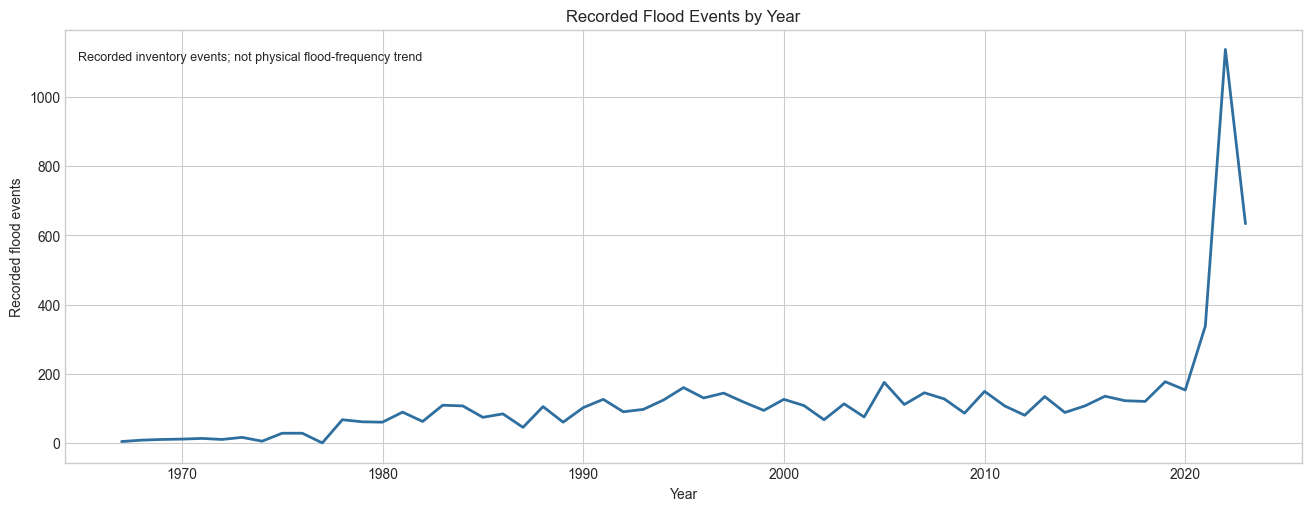

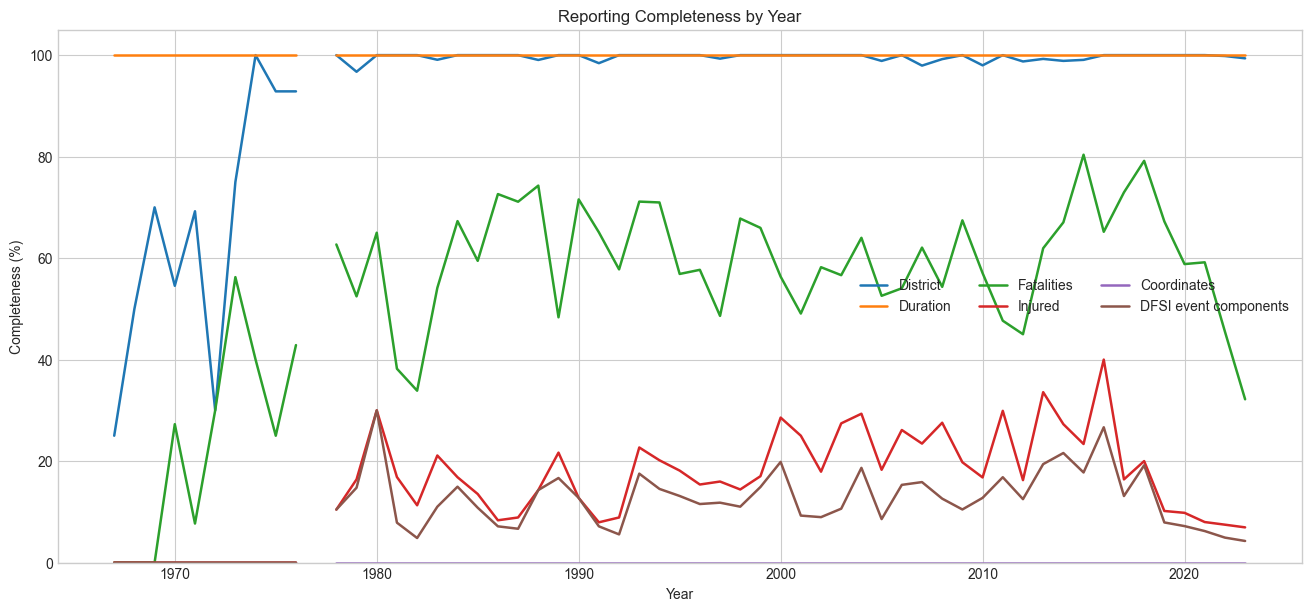

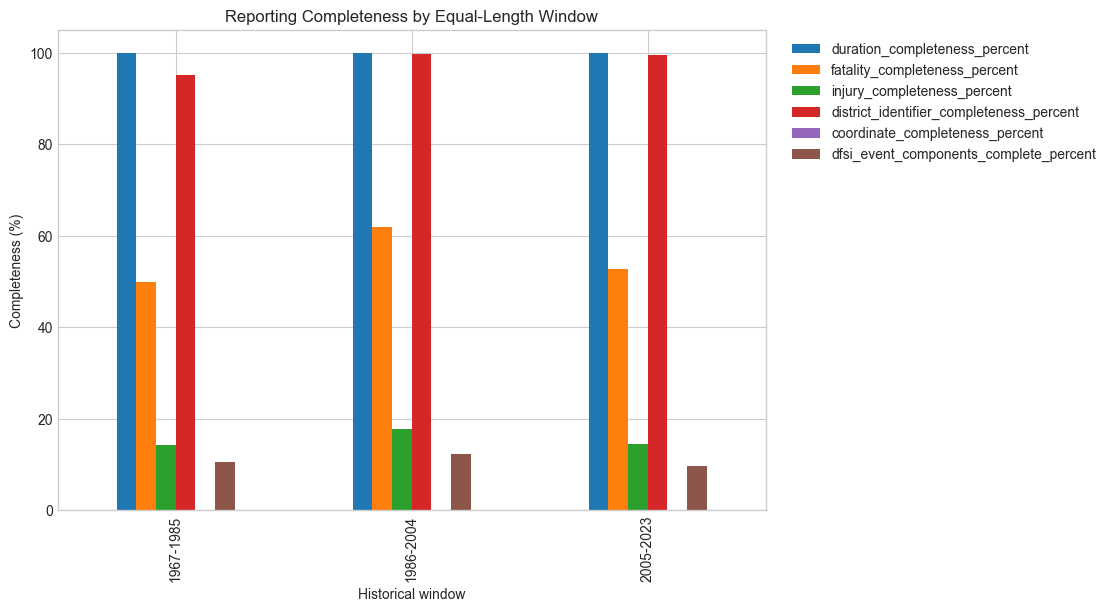

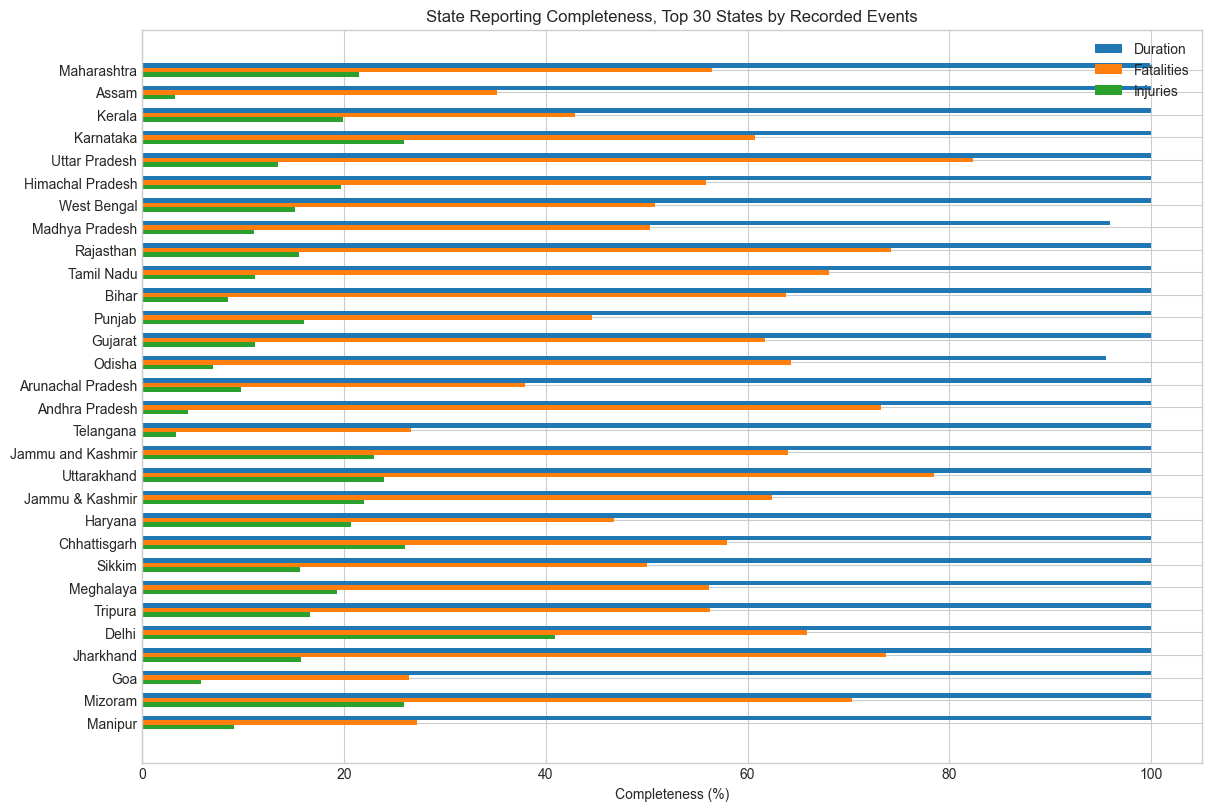

Saved figures:
- outputs/figures/flood_events_recorded_by_year.png (97,478 bytes)
- outputs/figures/reporting_completeness_by_year.png (258,087 bytes)
- outputs/figures/reporting_completeness_by_window.png (96,203 bytes)
- outputs/figures/state_reporting_completeness.png (141,689 bytes)


In [10]:
plt.style.use("seaborn-v0_8-whitegrid")

fig, ax = plt.subplots(figsize=(13, 5), constrained_layout=True)
ax.plot(annual_completeness["year"], annual_completeness["recorded_flood_events"], color="#2f6f9f", linewidth=2)
ax.set_title("Recorded Flood Events by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Recorded flood events")
ax.text(0.01, 0.95, "Recorded inventory events; not physical flood-frequency trend", transform=ax.transAxes, va="top", fontsize=9)
events_by_year_path = FIGURE_DIR / "flood_events_recorded_by_year.png"
fig.savefig(events_by_year_path, dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(13, 6), constrained_layout=True)
for column, label in [
    ("valid_district_percent", "District"),
    ("valid_duration_percent", "Duration"),
    ("fatalities_reported_percent", "Fatalities"),
    ("injured_reported_percent", "Injured"),
    ("coordinates_percent", "Coordinates"),
    ("dfsi_event_components_complete_percent", "DFSI event components"),
]:
    ax.plot(annual_completeness["year"], annual_completeness[column], linewidth=1.8, label=label)
ax.set_title("Reporting Completeness by Year")
ax.set_xlabel("Year")
ax.set_ylabel("Completeness (%)")
ax.set_ylim(0, 105)
ax.legend(ncol=3)
completeness_by_year_path = FIGURE_DIR / "reporting_completeness_by_year.png"
fig.savefig(completeness_by_year_path, dpi=200, bbox_inches="tight")
plt.show()

window_plot = window_completeness.set_index("window")[[
    "duration_completeness_percent",
    "fatality_completeness_percent",
    "injury_completeness_percent",
    "district_identifier_completeness_percent",
    "coordinate_completeness_percent",
    "dfsi_event_components_complete_percent",
]]
fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
window_plot.plot(kind="bar", ax=ax)
ax.set_title("Reporting Completeness by Equal-Length Window")
ax.set_xlabel("Historical window")
ax.set_ylabel("Completeness (%)")
ax.set_ylim(0, 105)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1.0))
window_completeness_path = FIGURE_DIR / "reporting_completeness_by_window.png"
fig.savefig(window_completeness_path, dpi=200, bbox_inches="tight")
plt.show()

state_plot = state_completeness.sort_values("total_events", ascending=False).head(30).copy()
fig, ax = plt.subplots(figsize=(12, 8), constrained_layout=True)
y = np.arange(len(state_plot))
ax.barh(y - 0.2, state_plot["duration_completeness_percent"], height=0.2, label="Duration")
ax.barh(y, state_plot["fatality_completeness_percent"], height=0.2, label="Fatalities")
ax.barh(y + 0.2, state_plot["injury_completeness_percent"], height=0.2, label="Injuries")
ax.set_yticks(y)
ax.set_yticklabels(state_plot["state_name"])
ax.invert_yaxis()
ax.set_title("State Reporting Completeness, Top 30 States by Recorded Events")
ax.set_xlabel("Completeness (%)")
ax.set_xlim(0, 105)
ax.legend()
state_completeness_path = FIGURE_DIR / "state_reporting_completeness.png"
fig.savefig(state_completeness_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved figures:")
for path in [events_by_year_path, completeness_by_year_path, window_completeness_path, state_completeness_path]:
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

## Validation and Required Answers

In [11]:
# Missing impact values were classified before numeric conversion and were never filled with zero.
for status_column in ["duration_status", "fatality_status", "injured_status"]:
    assert inventory_work[status_column].isin(["blank_value", "unavailable_or_unknown_value", "invalid_numeric_value"]).any(), (
        f"Expected explicit nonreported statuses in {status_column}; check missing-value classification."
    )
assert not any("fillna(0)" in str(value) for value in ["duration_numeric", "fatality_numeric", "injured_numeric"]), "Impact values must not be silently filled with zero."

RAW_HASH_AFTER = sha256_file(RAW_PATH)
assert RAW_HASH_BEFORE == RAW_HASH_AFTER, "data/raw inventory hash changed during audit."

annual_volume_change_ratio = annual_completeness["recorded_flood_events"].max() / max(annual_completeness.loc[annual_completeness["recorded_flood_events"].gt(0), "recorded_flood_events"].min(), 1)
window_event_counts = window_completeness["total_recorded_events"]
window_event_ratio = window_event_counts.max() / max(window_event_counts.min(), 1)
window_complete_range = window_completeness["dfsi_event_components_complete_percent"].max() - window_completeness["dfsi_event_components_complete_percent"].min()
missing_impact_rates = {
    "duration_missing_percent": 100 - inventory_work["valid_duration"].mean() * 100,
    "fatalities_missing_percent": 100 - inventory_work["fatalities_reported"].mean() * 100,
    "injuries_missing_percent": 100 - inventory_work["injured_reported"].mean() * 100,
}
most_missing_impacts = sorted(missing_impact_rates.items(), key=lambda item: item[1], reverse=True)

answer_summary = pd.DataFrame([
    {"question": "A. Has reporting volume changed substantially over time?", "answer": f"Yes. Annual recorded-event counts and equal-window totals vary substantially; window max/min event-count ratio is {window_event_ratio:.2f}. This is reporting volume, not a physical flood-frequency trend."},
    {"question": "B. Has reporting completeness changed substantially over time?", "answer": f"Yes. The range in window-level complete event-derived DFSI component coverage is {window_complete_range:.1f} percentage points, with larger annual variation visible in the audit tables."},
    {"question": "C. Which impact variables are most affected by missing reporting?", "answer": ", ".join(f"{name}: {value:.1f}% missing/nonreported" for name, value in most_missing_impacts)},
    {"question": "D. Are the three equal-length windows sufficiently comparable?", "answer": "No. They are equal length and non-overlapping, but recorded event volume, represented geographies, and completeness differ enough that direct temporal comparisons would be confounded by reporting completeness."},
    {"question": "E. Can a complete period-specific DFSI be reconstructed?", "answer": "No. Flooded-area percentage and population are not period-specific in this inventory, and event-derived impact fields contain missing/nonreported values."},
    {"question": "F. Can temporal sensitivity use only event-derived components?", "answer": "Yes, defensibly as a reporting-aware sensitivity analysis of event-derived components only: event frequency, duration, fatalities and injuries. It must not be described as complete period-specific DFSI."},
    {"question": "G. What limitations must be stated before making temporal claims?", "answer": "Recorded events are not physical flood-frequency trends; reporting completeness changes over time; state/district fields may contain multi-location lists; some LGD/district identifiers are missing; impact values distinguish zeros from missing; flooded area and population are static/unavailable by period in this file."},
])
display(answer_summary)
print(f"Raw SHA-256 after audit: {RAW_HASH_AFTER}")
print("Period-specific DFSI rankings were not constructed.")

,question,answer
0,A. Has reporting volume changed substantially over time?,"Yes. Annual recorded-event counts and equal-window totals vary substantially; window max/min event-count ratio is 5.41. This is reporting volume, not a physical flood-frequency..."
1,B. Has reporting completeness changed substantially over time?,"Yes. The range in window-level complete event-derived DFSI component coverage is 2.8 percentage points, with larger annual variation visible in the audit tables."
2,C. Which impact variables are most affected by missing reporting?,"injuries_missing_percent: 84.6% missing/nonreported, fatalities_missing_percent: 45.2% missing/nonreported, duration_missing_percent: 0.3% missing/nonreported"
3,D. Are the three equal-length windows sufficiently comparable?,"No. They are equal length and non-overlapping, but recorded event volume, represented geographies, and completeness differ enough that direct temporal comparisons would be conf..."
4,E. Can a complete period-specific DFSI be reconstructed?,"No. Flooded-area percentage and population are not period-specific in this inventory, and event-derived impact fields contain missing/nonreported values."
5,F. Can temporal sensitivity use only event-derived components?,"Yes, defensibly as a reporting-aware sensitivity analysis of event-derived components only: event frequency, duration, fatalities and injuries. It must not be described as comp..."
6,G. What limitations must be stated before making temporal claims?,Recorded events are not physical flood-frequency trends; reporting completeness changes over time; state/district fields may contain multi-location lists; some LGD/district ide...


Raw SHA-256 after audit: ef9ab2cd0db7bf917dcc22c7cb094ec599f5013ef1b96ba525d816f26ff1b108
Period-specific DFSI rankings were not constructed.


## Output Manifest

In [12]:
print("Saved outputs:")
for path in [
    TABLE_DIR / "flood_inventory_annual_completeness.csv",
    TABLE_DIR / "flood_inventory_decadal_completeness.csv",
    TABLE_DIR / "flood_inventory_window_completeness.csv",
    TABLE_DIR / "flood_inventory_state_completeness.csv",
    TABLE_DIR / "flood_inventory_missing_value_types.csv",
    TABLE_DIR / "temporal_analysis_feasibility.csv",
    TABLE_DIR / "temporal_reporting_flags.csv",
    FIGURE_DIR / "flood_events_recorded_by_year.png",
    FIGURE_DIR / "reporting_completeness_by_year.png",
    FIGURE_DIR / "reporting_completeness_by_window.png",
    FIGURE_DIR / "state_reporting_completeness.png",
]:
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

Saved outputs:
- outputs/tables/flood_inventory_annual_completeness.csv (5,406 bytes)
- outputs/tables/flood_inventory_decadal_completeness.csv (1,220 bytes)
- outputs/tables/flood_inventory_window_completeness.csv (1,039 bytes)
- outputs/tables/flood_inventory_state_completeness.csv (7,489 bytes)
- outputs/tables/flood_inventory_missing_value_types.csv (2,976 bytes)
- outputs/tables/temporal_analysis_feasibility.csv (3,137 bytes)
- outputs/tables/temporal_reporting_flags.csv (13,372 bytes)
- outputs/figures/flood_events_recorded_by_year.png (97,478 bytes)
- outputs/figures/reporting_completeness_by_year.png (258,087 bytes)
- outputs/figures/reporting_completeness_by_window.png (96,203 bytes)
- outputs/figures/state_reporting_completeness.png (141,689 bytes)
